In [13]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score
from sklearn.metrics import classification_report

# Load dataset with proper parsing
df = pd.read_csv(
    r"C:\Users\choua\Desktop\kaggle dataset\HepatitisCdata.csv",
    quotechar='"',
    na_values=['NA']
)

# Clean column names
df.columns = df.columns.str.replace('"', '').str.strip()

# Extract numeric class label from Category using regex
df['Category'] = df['Category'].str.extract(r'^(\d+)', expand=False).astype(int)

# Encode 'Sex' column (assuming it's a categorical feature)
df['Sex'] = df['Sex'].map({'m': 0, 'f': 1})

# Separate features and target
X = df.drop('Category', axis=1)
y = df['Category']

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define transformers
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

# Define models with preprocessing
xgboost_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(use_label_encoder=False, eval_metric='logloss'))
])

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier())
])

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(probability=True))
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Hyperparameters for tuning
xgb_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate': [0.01, 0.1]
}

rf_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5],
    'classifier__min_samples_split': [2, 5]
}

svm_params = {
    'classifier__C': [0.1, 1, 10],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto']
}

# Run Grid Search
xgb_search = GridSearchCV(xgboost_model, xgb_params, cv=5, scoring='accuracy')
xgb_search.fit(X_train, y_train)

rf_search = GridSearchCV(rf_model, rf_params, cv=5, scoring='accuracy')
rf_search.fit(X_train, y_train)

svm_search = GridSearchCV(svm_model, svm_params, cv=5, scoring='accuracy')
svm_search.fit(X_train, y_train)

# Get best models
best_xgb = xgb_search.best_estimator_
best_rf = rf_search.best_estimator_
best_svm = svm_search.best_estimator_

# Evaluate on test set
print("Best XGBoost Accuracy:", best_xgb.score(X_test, y_test))
print("Best Random Forest Accuracy:", best_rf.score(X_test, y_test))
print("Best SVM Accuracy:", best_svm.score(X_test, y_test))

# Classification Reports
print("\nXGBoost Classification Report:")
print(classification_report(y_test, best_xgb.predict(X_test)))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, best_rf.predict(X_test)))

print("\nSVM Classification Report:")
print(classification_report(y_test, best_svm.predict(X_test)))

# Cross-validation scores (F1-macro due to multi-class)
xgb_cv_scores = cross_val_score(best_xgb, X_train, y_train, cv=5, scoring='f1_macro')
rf_cv_scores = cross_val_score(best_rf, X_train, y_train, cv=5, scoring='f1_macro')
svm_cv_scores = cross_val_score(best_svm, X_train, y_train, cv=5, scoring='f1_macro')

print("\nXGBoost Cross-Validated F1-Score (Macro):", xgb_cv_scores.mean())
print("Random Forest Cross-Validated F1-Score (Macro):", rf_cv_scores.mean())
print("SVM Cross-Validated F1-Score (Macro):", svm_cv_scores.mean())

c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:00] WARNING: C:\actio

Best XGBoost Accuracy: 0.991869918699187
Best Random Forest Accuracy: 0.967479674796748
Best SVM Accuracy: 0.9024390243902439

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        99
           1       1.00      1.00      1.00         9
           2       0.86      1.00      0.92         6
           3       1.00      0.89      0.94         9

    accuracy                           0.99       123
   macro avg       0.96      0.97      0.97       123
weighted avg       0.99      0.99      0.99       123


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        99
           1       0.89      0.89      0.89         9
           2       0.62      0.83      0.71         6
           3       1.00      0.78      0.88         9

    accuracy                           0.97       123
   macro avg       0.88      0.88      0.87

c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:33:11] WARNING: C:\actio


XGBoost Cross-Validated F1-Score (Macro): 0.94340799031477
Random Forest Cross-Validated F1-Score (Macro): 0.8432196786264583
SVM Cross-Validated F1-Score (Macro): 0.7001819594316262


C:\Users\choua\AppData\Local\Temp\ipykernel_4760\4187019463.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='XGBoost', y='Feature', data=importance_df, ax=ax[0], palette="viridis")
C:\Users\choua\AppData\Local\Temp\ipykernel_4760\4187019463.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Random Forest', y='Feature', data=importance_df, ax=ax[1], palette="plasma")


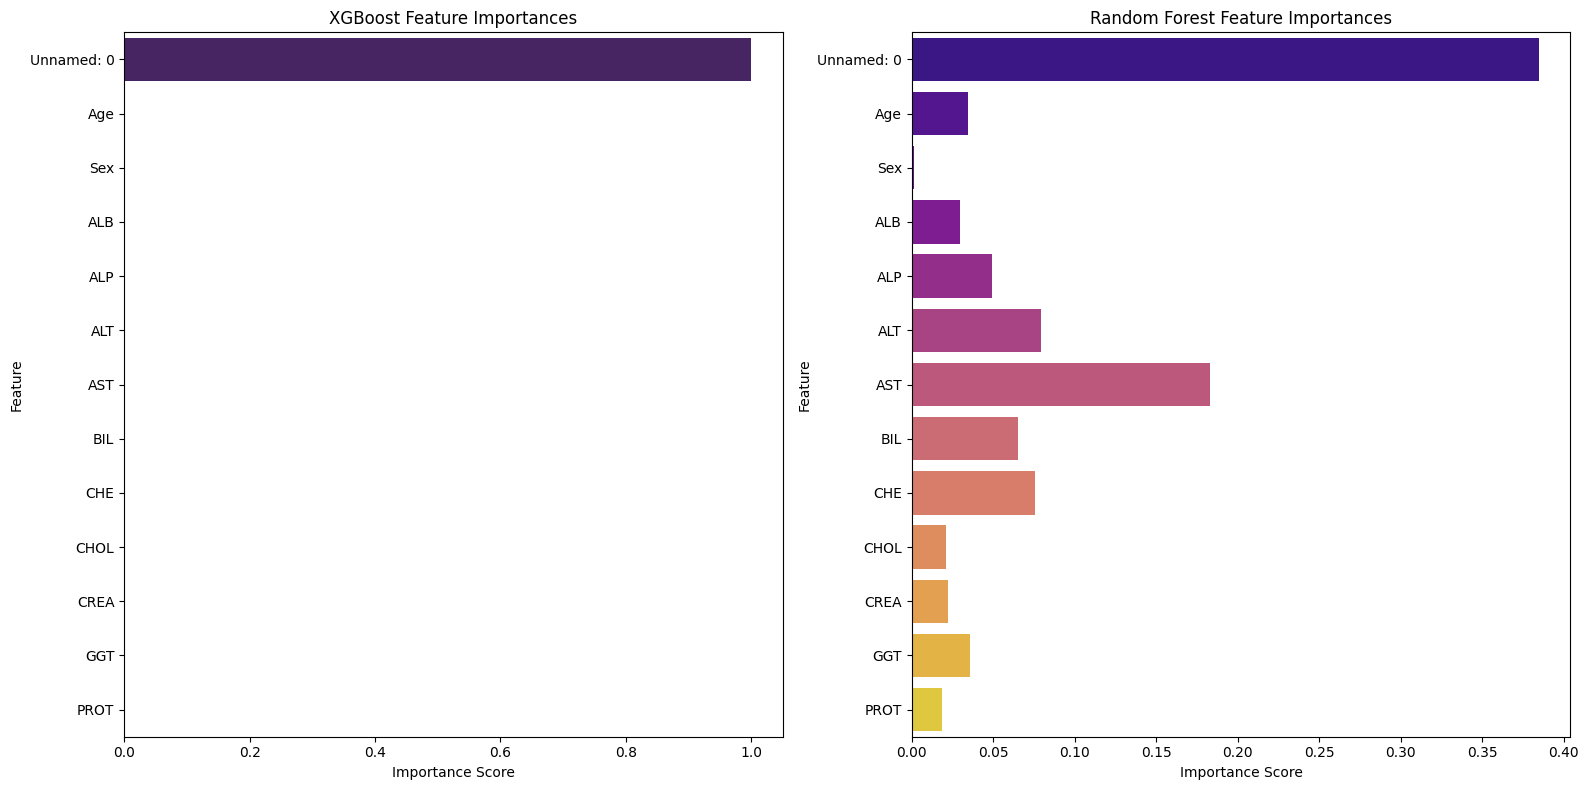

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get feature names (from your original cleaned dataset)
feature_names = X.columns.tolist()

# Extract feature importances from best models
xgb_importances = best_xgb.named_steps['classifier'].feature_importances_
rf_importances = best_rf.named_steps['classifier'].feature_importances_

# Create DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'XGBoost': xgb_importances,
    'Random Forest': rf_importances
})

# Sort by XGBoost importance
importance_df = importance_df.sort_values(by='XGBoost', ascending=False)

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

# XGBoost
sns.barplot(x='XGBoost', y='Feature', data=importance_df, ax=ax[0], palette="viridis")
ax[0].set_title("XGBoost Feature Importances")
ax[0].set_xlabel("Importance Score")

# Random Forest
sns.barplot(x='Random Forest', y='Feature', data=importance_df, ax=ax[1], palette="plasma")
ax[1].set_title("Random Forest Feature Importances")
ax[1].set_xlabel("Importance Score")

plt.tight_layout()
plt.show()

c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Best LogisticRegression Params: {'classifier__C': 0.1, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
LogisticRegression Best Accuracy: 0.9492475778190064
Best KNN Params: {'classifier__n_neighbors': 3, 'classifier__weights': 'uniform'}
KNN Best Accuracy: 0.9431663574520718
Best SVM Params: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
SVM Best Accuracy: 0.9512265512265513
Best RandomForest Params: {'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
RandomForest Best Accuracy: 0.9796742939600082
Best GaussianNB Params: {'classifier__var_smoothing': 1e-09}
GaussianNB Best Accuracy: 0.9572871572871573

Ensemble Model Accuracy: 0.975609756097561
Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       108
           1       1.00      0.60      0.75         5
           2       0.67      1.00      0.80         4
          

<Figure size 1000x600 with 0 Axes>

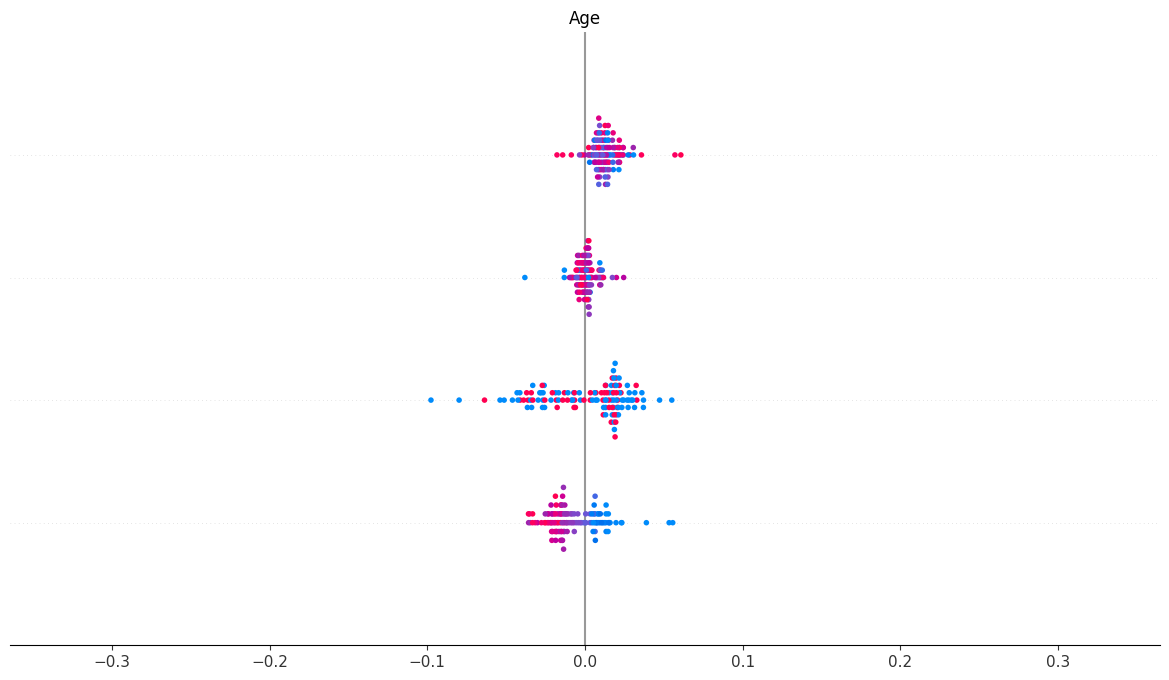

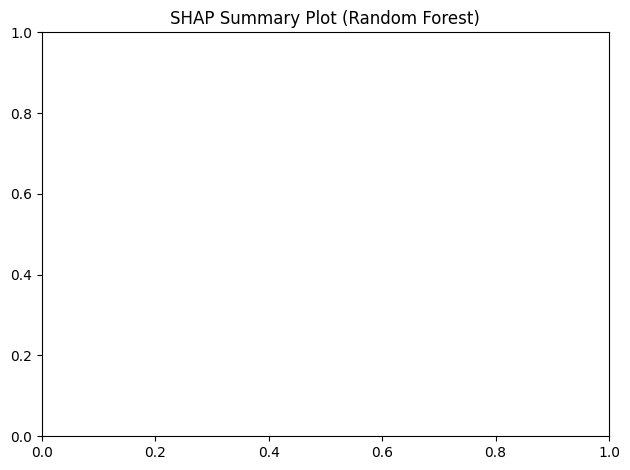

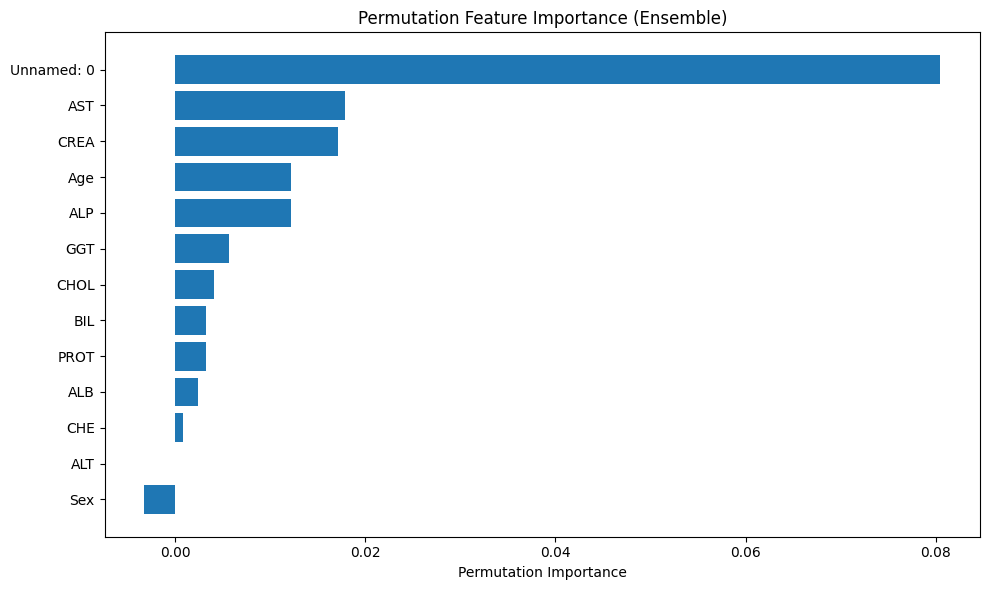

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
import shap

# ---------------------
# 1. Load and Preprocess Data
# ---------------------

# Load dataset
df = pd.read_csv(r"C:\Users\choua\Desktop\kaggle dataset\HepatitisCdata.csv", quotechar='"', na_values=['NA'])

# Clean column names
df.columns = df.columns.str.replace('"', '').str.strip()

# Extract numeric class label from Category
df['Category'] = df['Category'].str.extract(r'^(\d+)', expand=False).astype(int)

# Encode 'Sex' (assuming it's the only categorical feature)
df['Sex'] = df['Sex'].map({'m': 0, 'f': 1})

# Separate features and target
X = df.drop('Category', axis=1)
y = df['Category']

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define preprocessing pipeline
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ---------------------
# 2. Define Base Models with Hyperparameter Grids
# ---------------------

# Logistic Regression
lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

lr_params = {
    'classifier__C': [0.1, 1, 10],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear']
}

# K-Nearest Neighbors
knn_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

knn_params = {
    'classifier__n_neighbors': [3, 5, 7],
    'classifier__weights': ['uniform', 'distance']
}

# Support Vector Machine
svm_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(probability=True, kernel='rbf', class_weight='balanced'))
])

svm_params = {
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 'auto', 0.1, 1],
    'classifier__kernel': ['linear', 'rbf']
}

# Random Forest
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

rf_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 5]
}

# Naive Bayes
gnb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

gnb_params = {
    'classifier__var_smoothing': [1e-9, 1e-5, 1e-1]
}

# ---------------------
# 3. Run GridSearchCV for Each Model
# ---------------------

# Function to run GridSearchCV
def run_grid_search(model, params, name):
    grid = GridSearchCV(model, params, cv=5, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    print(f"Best {name} Params:", grid.best_params_)
    print(f"{name} Best Accuracy:", grid.best_score_)
    return grid

# Run GridSearchCV for each model
lr_search = run_grid_search(lr_pipe, lr_params, "LogisticRegression")
knn_search = run_grid_search(knn_pipe, knn_params, "KNN")
svm_search = run_grid_search(svm_pipe, svm_params, "SVM")
rf_search = run_grid_search(rf_pipe, rf_params, "RandomForest")
gnb_search = run_grid_search(gnb_pipe, gnb_params, "GaussianNB")

# Extract best models
best_models = [
    ('lr', lr_search.best_estimator_.named_steps['classifier']),
    ('knn', knn_search.best_estimator_.named_steps['classifier']),
    ('svc', svm_search.best_estimator_.named_steps['classifier']),
    ('rf', rf_search.best_estimator_.named_steps['classifier']),
    ('gnb', gnb_search.best_estimator_.named_steps['classifier'])
]

# ---------------------
# 4. Build Voting Ensemble with Best Models
# ---------------------

# Voting Classifier with best models
voting_clf = VotingClassifier(estimators=best_models, voting='soft', n_jobs=-1)

# Wrap with preprocessor
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', voting_clf)
])

# Fit and evaluate
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

print("\nEnsemble Model Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# ---------------------
# 5. SHAP Analysis for Random Forest (Tree-based)
# ---------------------

# Extract preprocessor and random forest model
rf_pipeline = rf_search.best_estimator_
rf_model = rf_pipeline.named_steps['classifier']
preprocessor_rf = rf_pipeline.named_steps['preprocessor']

# Transform test data using the same preprocessor
X_test_processed = preprocessor_rf.transform(X_test)

# SHAP explainer
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_processed)

# Plot SHAP summary
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_processed, feature_names=X.columns)
plt.title("SHAP Summary Plot (Random Forest)")
plt.tight_layout()
plt.show()

# Optional: Permutation Importance
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(model_pipeline, X_test, y_test, n_repeats=10, random_state=42)
sorted_idx = perm_result.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_idx], perm_result.importances_mean[sorted_idx])
plt.xlabel("Permutation Importance")
plt.title("Permutation Feature Importance (Ensemble)")
plt.tight_layout()
plt.show()

StackingClassifier Accuracy: 0.975609756097561

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       108
           1       1.00      0.80      0.89         5
           2       0.60      0.75      0.67         4
           3       0.83      0.83      0.83         6

    accuracy                           0.98       123
   macro avg       0.86      0.85      0.85       123
weighted avg       0.98      0.98      0.98       123



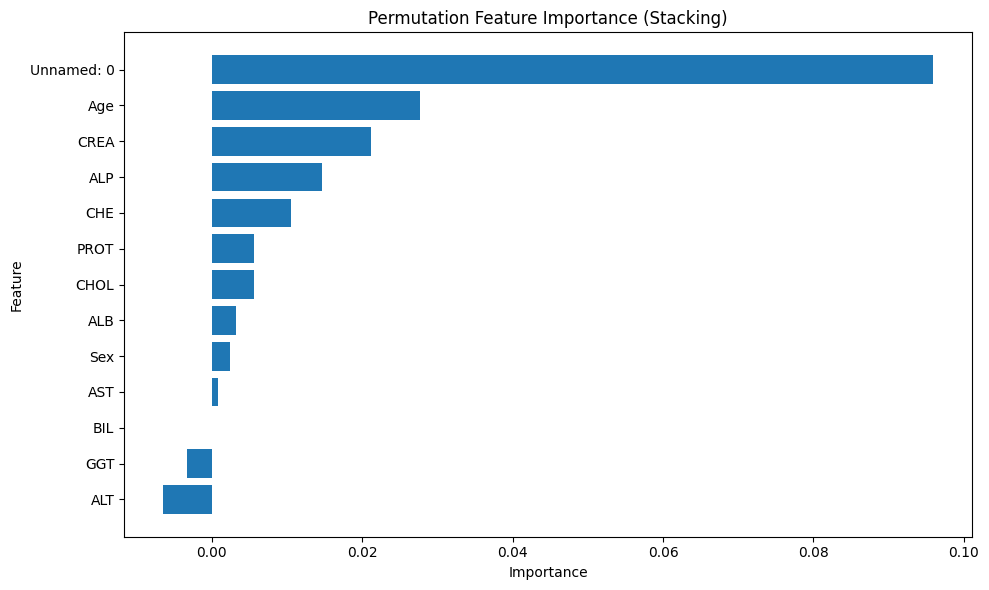

<Figure size 1000x600 with 0 Axes>

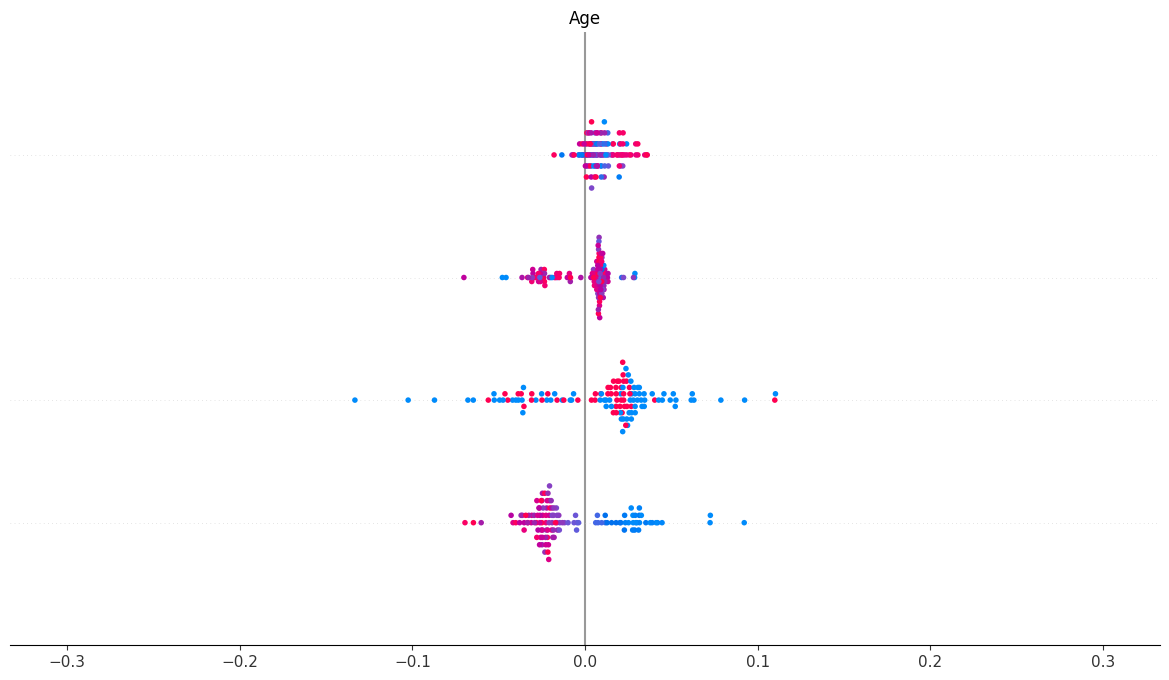

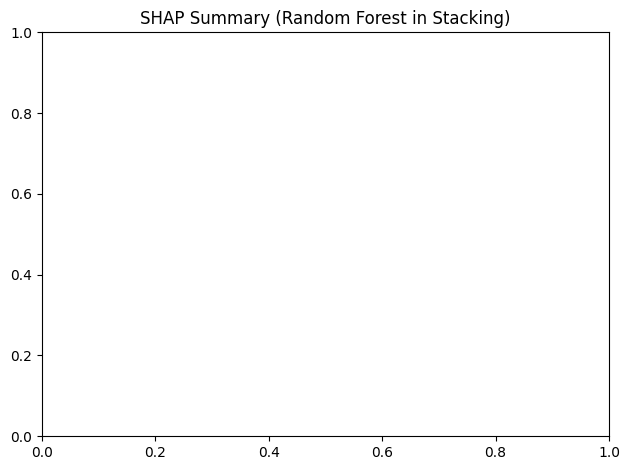

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report
from imblearn.pipeline import Pipeline as imbpipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.inspection import permutation_importance
import shap

# ---------------------
# 1. Load and Preprocess Data
# ---------------------

# Load dataset
df = pd.read_csv(r"C:\Users\choua\Desktop\kaggle dataset\HepatitisCdata.csv", quotechar='"', na_values=['NA'])

# Clean column names
df.columns = df.columns.str.replace('"', '').str.strip()

# Extract numeric class label
df['Category'] = df['Category'].str.extract(r'^(\d+)', expand=False).astype(int)

# Encode 'Sex' (categorical feature)
df['Sex'] = df['Sex'].map({'m': 0, 'f': 1})

# Separate features and target
X = df.drop('Category', axis=1)
y = df['Category']

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Define preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
], remainder='drop')

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ---------------------
# 2. Define Base Models for Stacking
# ---------------------

# Define base models
base_models = [
    ('lr', LogisticRegression(C=1, penalty='l2', solver='liblinear', max_iter=1000)),
    ('knn', KNeighborsClassifier(n_neighbors=5, weights='uniform')),
    ('svc', SVC(C=1, kernel='rbf', probability=True)),
    ('rf', RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced')),
    ('gnb', GaussianNB(var_smoothing=1e-9))
]

# Define meta-estimator
meta_model = LogisticRegression()

# ---------------------
# 3. Build Stacking Pipeline with SMOTE
# ---------------------

# Use imblearn's Pipeline to handle resampling
stacking_pipeline = imbpipeline([
    ('preprocessor', preprocessor),
    ('resample', SMOTE(random_state=42)),  # Use RandomUnderSampler() for undersampling
    ('stacking', StackingClassifier(
        estimators=base_models,
        final_estimator=meta_model,
        n_jobs=-1,
        verbose=True
    ))
])

# Fit and evaluate
stacking_pipeline.fit(X_train, y_train)
y_pred = stacking_pipeline.predict(X_test)

print("StackingClassifier Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# ---------------------
# 4. Permutation Importance
# ---------------------

# Get processed test data
X_test_processed = stacking_pipeline.named_steps['preprocessor'].transform(X_test)

# Compute permutation importance
perm_result = permutation_importance(stacking_pipeline, X_test, y_test, n_repeats=10, random_state=42)
sorted_idx = perm_result.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_idx], perm_result.importances_mean[sorted_idx])
plt.title("Permutation Feature Importance (Stacking)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# ---------------------
# 5. SHAP Analysis for Base Random Forest
# ---------------------

# Extract preprocessor and random forest model from stacking
rf_model = stacking_pipeline.named_steps['stacking'].named_estimators_['rf']
preprocessor_rf = stacking_pipeline.named_steps['preprocessor']

# Transform test data
X_test_processed = preprocessor_rf.transform(X_test)

# SHAP explainer
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_processed)

# Plot SHAP summary
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_processed, feature_names=X.columns)
plt.title("SHAP Summary (Random Forest in Stacking)")
plt.tight_layout()
plt.show()